Welcome to Part 1. The prerequisites gave you the biology; now we compute with it. Bioinformatics is, at bottom, string processing on molecular sequences, and this first chapter sets up the tools and habits for everything that follows: fetching real data, treating a genome as a Python string, and extracting biology from it with simple, fast algorithms. By the end you will have rediscovered genes and a bacterial replication origin from raw sequence.

:::eli5
A genome is a very long text written in a four-letter alphabet. Once it is a string in your program you can do with it what you would with any text: count letters, look for repeated words, search for patterns, measure how one region differs from another. Surprisingly much of biology falls straight out of such counting. Where the letters are lopsided, a chromosome starts copying itself; where a long stretch runs without a "stop" word, there is probably a gene.
:::

## Getting real data: NCBI and FASTA

The world's DNA and protein sequences live in a few public databases, chiefly **GenBank** at the US National Center for Biotechnology Information (**NCBI**), mirrored in Europe (ENA) and Japan (DDBJ). Anyone can download any sequence for free. The simplest access is NCBI's **E-utilities** web service: ask for a record by its **accession number** and get back text. We have saved three records so the chapter runs offline:

- `NC_045512` — the SARS-CoV-2 (COVID-19) reference genome, with gene annotations (GenBank format).
- `NC_001416` — phage lambda, from the prerequisites.
- the first 100 kb of `NC_000913`, the *E. coli* K-12 genome, with its genes annotated.

:::data
To fetch any record yourself (with a network connection), E-utilities takes a URL like
`https://eutils.ncbi.nlm.nih.gov/entrez/eutils/efetch.fcgi?db=nuccore&id=NC_045512&rettype=fasta&retmode=text`.
Change `id` for any accession, and `rettype` to `gb` for the annotated GenBank record. Biopython wraps this in `Bio.Entrez`; always set `Entrez.email` and stay within NCBI's rate limits (3 requests/second without an API key).
:::

The plainest format is **FASTA**: a header line starting with `>`, then the sequence. **GenBank** format adds a **feature table** listing where each gene, CDS and other element sits. Biopython reads both:

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from pathlib import Path
from collections import Counter
from Bio import SeqIO
import warnings; warnings.filterwarnings("ignore")

mpl.rc("figure", dpi=110); mpl.rc("axes", labelsize=12, titlesize=13)
IMAGES = Path("images"); IMAGES.mkdir(exist_ok=True)
def save_fig(name):
    plt.tight_layout(); plt.savefig(IMAGES / f"{name}.png", dpi=150, bbox_inches="tight")
R = {}

cov = SeqIO.read("datasets/sarscov2.gb", "genbank")
genes = [f for f in cov.features if f.type == "CDS"]
print(f"{cov.id}: {len(cov.seq):,} bases, {cov.annotations['organism']}")
print(f"{len(genes)} annotated protein-coding genes")
for f in genes[:4]:
    name = f.qualifiers.get("gene", ["?"])[0]
    loc = f.location
    print(f"  {name:8s} {int(loc.start) + 1:>6}-{int(loc.end):<6} ({len(f.location) // 3 - 1} codons)")
R["cov_len"] = f"{len(cov.seq):,}"; R["cov_genes"] = len(genes)

NC_045512.2: 29,903 bases, Severe acute respiratory syndrome coronavirus 2
12 annotated protein-coding genes
  ORF1ab      266-21555  (7096 codons)
  ORF1ab      266-13483  (4405 codons)
  S         21563-25384  (1273 codons)
  ORF3a     25393-26220  (275 codons)


A genome is now a Python object whose `.seq` behaves like a string. Everything below is counting and slicing on that string.

## Composition and GC content

The simplest statistic is base composition. For SARS-CoV-2 (an RNA virus stored with T for U, prerequisite P3):

In [2]:
seq = str(cov.seq)
comp = Counter(seq)
n = len(seq)
for b in "ACGT":
    print(f"{b}: {comp[b]:>6,}  ({comp[b] / n:.1%})")
gc = (comp["G"] + comp["C"]) / n
print(f"GC content: {gc:.1%}")
R["cov_gc"] = f"{gc:.0%}"; R["cov_a"] = f"{comp['A'] / n:.0%}"; R["cov_t"] = f"{comp['T'] / n:.0%}"

A:  8,954  (29.9%)
C:  5,492  (18.4%)
G:  5,863  (19.6%)
T:  9,594  (32.1%)
GC content: 38.0%


SARS-CoV-2 is only about 38% GC and strikingly A/T-rich (30% A, 32% T): a lopsided genome, which prerequisite P3 linked to antiviral editing enzymes. GC content varies *along* a genome too, and a sliding window reveals the structure. Let's compare the uniform-ish virus with the first 100 kb of *E. coli*:

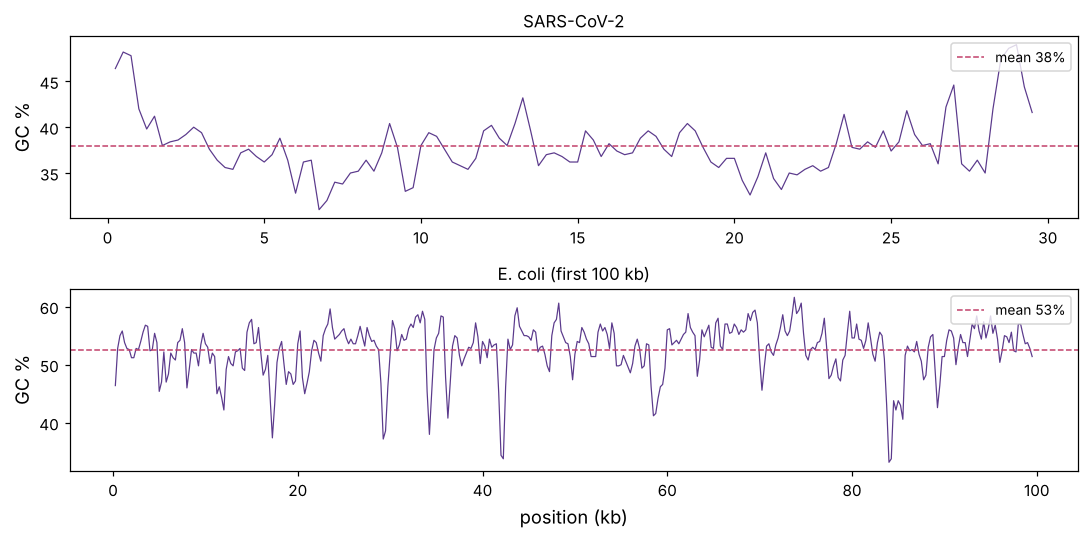

In [3]:
ecoli = SeqIO.read("datasets/ecoli_100kb.gb", "genbank")

def gc_windows(s, w=500, step=250):
    s = str(s)
    pos = np.arange(0, len(s) - w, step)
    gc = np.array([(s[p:p + w].count("G") + s[p:p + w].count("C")) / w for p in pos])
    return pos + w / 2, gc

fig, axs = plt.subplots(2, 1, figsize=(10, 5))
for ax, (name, rec) in zip(axs, [("SARS-CoV-2", cov), ("E. coli (first 100 kb)", ecoli)]):
    x, g = gc_windows(rec.seq, w=500)
    ax.plot(x / 1000, 100 * g, color="#5b3a8c", lw=0.8)
    whole = (str(rec.seq).count("G") + str(rec.seq).count("C")) / len(rec.seq)
    ax.axhline(100 * whole, color="#c2416b", ls="--", lw=1, label=f"mean {whole:.0%}")
    ax.set_title(name, fontsize=11); ax.set_ylabel("GC %"); ax.legend(loc="upper right", fontsize=9)
axs[1].set_xlabel("position (kb)")
save_fig("gc_content"); plt.show()
R["ecoli_gc"] = f"{(str(ecoli.seq).count('G') + str(ecoli.seq).count('C')) / len(ecoli.seq):.0%}"

![Figure 1-1. GC content in 500-base windows. SARS-CoV-2 hovers around 38%; E. coli around 51%, with local dips (some AT-rich regions are regulatory or horizontally acquired).](images/gc_content.png)

*E. coli* sits near 53% GC. Local GC dips often mark regulatory regions or DNA acquired from other organisms (prerequisite P3's lambda example). The playground's second tab computes this live.

::playground animations/seq_lab.html 620

## GC skew: finding the replication origin

Here is a result that feels like magic. Count, as you walk along one strand, the running total of (number of G) − (number of C). On most of a bacterial chromosome this **cumulative GC skew** drifts steadily in one direction, then reverses. The turning points mark the **origin** and **terminus** of replication.

Why? When DNA is copied (prerequisite P3), the two strands are replicated differently: one continuously (leading), one in pieces (lagging). The leading strand sits exposed as single-stranded DNA for longer, where cytosine spontaneously deaminates to thymine, so over evolutionary time the leading strand loses Cs and gains the skew. The skew flips sign at the origin, where the direction of replication flips. Let's use the whole *E. coli* genome region:

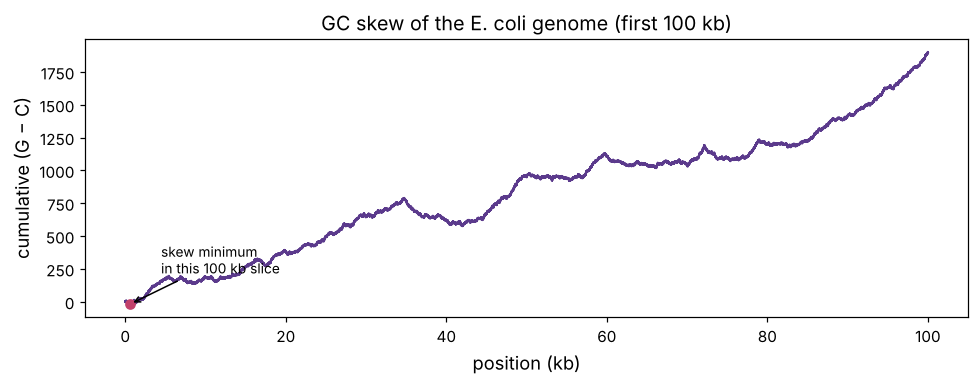

In [4]:
def cumulative_skew(s):
    s = str(s)
    skew = np.zeros(len(s) + 1)
    for i, b in enumerate(s):
        skew[i + 1] = skew[i] + (b == "G") - (b == "C")
    return skew

skew = cumulative_skew(ecoli.seq)
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(np.arange(len(skew)) / 1000, skew, color="#5b3a8c")
argmin = skew.argmin()
ax.scatter(argmin / 1000, skew[argmin], color="#c2416b", zorder=3)
ax.annotate("skew minimum\nin this 100 kb slice", (argmin / 1000, skew[argmin]), xytext=(20, 20), textcoords="offset points", fontsize=9, arrowprops=dict(arrowstyle="->"))
ax.set_xlabel("position (kb)"); ax.set_ylabel("cumulative (G − C)")
ax.set_title("GC skew of the E. coli genome (first 100 kb)")
save_fig("gc_skew"); plt.show()
R["skew_min"] = f"{argmin / 1000:.0f}"

![Figure 1-2. Cumulative GC skew along the E. coli region. The real origin of replication (oriC) sits near base 3.9 Mb in the full genome; in this 100 kb slice the skew trends in one direction, part of the global V-shape.](images/gc_skew.png)

On the **whole** 4.6 Mb *E. coli* chromosome this plot is a clean V whose minimum lands right on the experimentally known origin, *oriC*. We only saved 100 kb, so you see one arm of the V, but the principle is exact, and the skew-minimum method is a standard first step when annotating a new bacterial genome. (The playground draws the cumulative skew for its shorter sequences too.)

## k-mers: the words of a genome

Break a sequence into all overlapping substrings of length $k$ (**k-mers**) and count them. k-mers are everywhere in bioinformatics: they summarise composition, drive fast database search (next chapter) and underlie genome assembly (chapter 4). How many are there, and how are they distributed?

In [5]:
def kmer_counts(s, k):
    s = str(s)
    c = Counter(s[i:i + k] for i in range(len(s) - k + 1) if set(s[i:i + k]) <= set("ACGT"))
    return c

for k in (1, 2, 3, 4):
    c = kmer_counts(ecoli.seq, k)
    total = sum(c.values())
    top = c.most_common(1)[0]
    rare = min(c.items(), key=lambda kv: kv[1])
    print(f"k={k}: {4 ** k:4d} possible, {len(c):4d} seen; commonest {top[0]} ({top[1] / total:.1%}), rarest {rare[0]} ({rare[1] / total:.2%})")

k=1:    4 possible,    4 seen; commonest G (27.2%), rarest A (23.30%)
k=2:   16 possible,   16 seen; commonest GC (8.9%), rarest TA (4.08%)
k=3:   64 possible,   64 seen; commonest GCG (2.9%), rarest CTA (0.53%)
k=4:  256 possible,  256 seen; commonest GGCG (1.0%), rarest CTAG (0.02%)


The counts are uneven: real genomes are not random strings. Some words are avoided. A classic case: the palindrome `CTAG` and certain others are under-represented in many bacteria, partly to avoid restriction sites (prerequisite P3) and partly from how codons are used. Let's quantify over/under-representation as observed/expected:

In [6]:
def kmer_enrichment(s, k=4):
    s = str(s)
    obs = kmer_counts(s, k)
    mono = Counter(b for b in s if b in "ACGT")
    N = sum(mono.values())
    total_k = sum(obs.values())
    rows = []
    for word, o in obs.items():
        expected = total_k * np.prod([mono[b] / N for b in word])   # expected from single-base frequencies
        rows.append((word, o, expected, o / expected))
    return sorted(rows, key=lambda r: r[3])

rows = kmer_enrichment(ecoli.seq, 4)
print("most under-represented 4-mers:")
for w, o, e, ratio in rows[:5]:
    print(f"  {w}: observed {o}, expected {e:.0f}, ratio {ratio:.2f}")
print("most over-represented:")
for w, o, e, ratio in rows[-5:]:
    print(f"  {w}: observed {o}, expected {e:.0f}, ratio {ratio:.2f}")
R["under"] = rows[0][0]; R["under_ratio"] = f"{rows[0][3]:.2f}"

most under-represented 4-mers:
  CTAG: observed 18, expected 388, ratio 0.05
  CCTA: observed 69, expected 361, ratio 0.19
  TAGG: observed 93, expected 417, ratio 0.22
  GAGG: observed 162, expected 471, ratio 0.34
  TAGA: observed 123, expected 357, ratio 0.34
most over-represented:
  CAGC: observed 777, expected 408, ratio 1.91
  GGCG: observed 1024, expected 512, ratio 2.00
  TTTT: observed 687, expected 338, ratio 2.03
  GCTG: observed 948, expected 454, ratio 2.09
  AAAA: observed 693, expected 295, ratio 2.35


The most avoided 4-mer in this region is `CTAG` (observed/expected 0.05). Deviations like this are biological signals, not noise, and k-mer spectra are used to classify organisms, detect contamination and bin metagenomic reads. The playground ranks k-mers for any sequence, colouring over- and under-represented ones.

## Finding genes: open reading frames

A protein-coding gene is read in-frame from a start codon (ATG) to a stop (prerequisite P4). A stretch from ATG to the next in-frame stop, with no stop between, is an **open reading frame** (ORF). Because any of the 6 frames (3 forward, 3 on the reverse complement) could carry a gene, and because stops occur about every 21 codons in random DNA, a *long* ORF is strong evidence of a real gene. Let's build a six-frame ORF finder and test it on SARS-CoV-2.

In [7]:
B = "TCAG"; AAS = "FFLLSSSSYY**CC*WLLLLPPPPHHQQRRRRIIIMTTTTNNKKSSRRVVVVAAAADDEEGGGG"
CODE = {a + b + c: AAS[16 * i + 4 * j + k] for i, a in enumerate(B) for j, b in enumerate(B) for k, c in enumerate(B)}

def find_orfs(seq, min_codons=50):
    seq = str(seq).upper()
    rc = seq[::-1].translate(str.maketrans("ACGT", "TGCA"))
    orfs = []
    for strand, s in [(+1, seq), (-1, rc)]:
        for frame in range(3):
            start = None
            for i in range(frame, len(s) - 2, 3):
                codon = s[i:i + 3]
                if start is None and codon == "ATG":
                    start = i
                elif start is not None and CODE.get(codon) == "*":
                    if (i - start) // 3 >= min_codons:
                        a, b = (start, i + 3) if strand == 1 else (len(s) - i - 3, len(s) - start)
                        orfs.append((a, b, strand, (i - start) // 3))
                    start = None
    return sorted(orfs, key=lambda o: -o[3])

orfs = find_orfs(cov.seq, min_codons=50)
print(f"{len(orfs)} ORFs of 50+ codons in SARS-CoV-2")
for a, b, strand, length in orfs[:6]:
    print(f"  {a + 1:>6}-{b:<6} strand {strand:+d}  {length:>4} codons")
R["n_orfs"] = len(orfs); R["longest_orf"] = f"{orfs[0][3]:,}"

47 ORFs of 50+ codons in SARS-CoV-2
     266-13483  strand +1  4405 codons
   13768-21555  strand +1  2595 codons
   21536-25384  strand +1  1282 codons
   28274-29533  strand +1   419 codons
   25393-26220  strand +1   275 codons
   26523-27191  strand +1   222 codons


The longest single ORF is about 4,405 codons: that is **ORF1a**, the first part of the giant replicase polyprotein. The full **ORF1ab** is even longer, but the virus makes it with a programmed −1 **ribosomal frameshift** partway along, so no single open reading frame spans it, which is exactly why our frame-bound finder stops early. A reminder that genes do not always equal ORFs. How well do our ORFs match the real genes? Let's compare predicted ORF start/stop positions with the annotated CDS features:

predicted ORFs (40+ codons): 70; sharing a stop with a real gene: 11
real genes recovered: 11 of 12


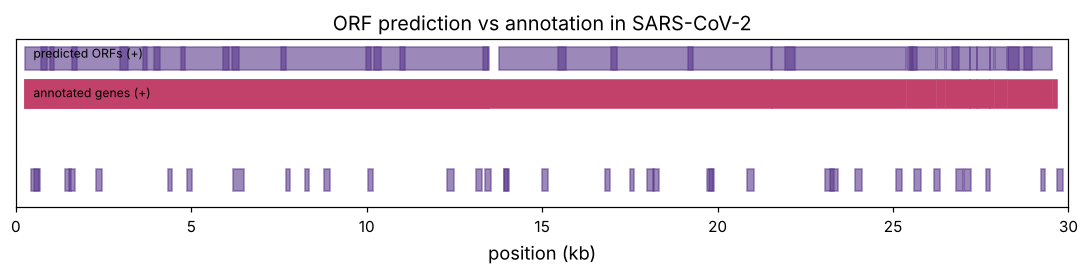

In [8]:
annotated = set()
for f in genes:
    annotated.add((int(f.location.start), int(f.location.end), f.location.strand))
pred = {(a, b, strand) for a, b, strand, _ in find_orfs(cov.seq, min_codons=40)}

def overlaps_annotation(orf, tol=0):
    a, b, strand = orf
    for sa, sb, sstrand in annotated:
        if strand == sstrand and abs(b - sb) <= 3:          # same stop codon = same gene
            return True
    return False

hits = sum(overlaps_annotation(o) for o in pred)
found_genes = sum(any(abs(b - sb) <= 3 and strand == sstrand for a, b, strand in pred) for sa, sb, sstrand in annotated)
print(f"predicted ORFs (40+ codons): {len(pred)}; sharing a stop with a real gene: {hits}")
print(f"real genes recovered: {found_genes} of {len(annotated)}")
fig, ax = plt.subplots(figsize=(10, 2.6))
for sa, sb, sstrand in annotated:
    ax.add_patch(plt.Rectangle((sa / 1000, 0.55 if sstrand == 1 else 0.25), (sb - sa) / 1000, 0.18, color="#c2416b"))
for a, b, strand, length in find_orfs(cov.seq, 40):
    ax.add_patch(plt.Rectangle((a / 1000, 0.8 if strand == 1 else 0.0), (b - a) / 1000, 0.15, color="#5b3a8c", alpha=0.6))
ax.text(0.5, 0.88, "predicted ORFs (+)", fontsize=8); ax.text(0.5, 0.62, "annotated genes (+)", fontsize=8)
ax.set_xlim(0, 30); ax.set_ylim(-0.1, 1.0); ax.set_yticks([]); ax.set_xlabel("position (kb)")
ax.set_title("ORF prediction vs annotation in SARS-CoV-2")
save_fig("orf_map"); plt.show()
R["found_genes"] = found_genes; R["n_annot"] = len(annotated)

![Figure 1-3. Predicted ORFs (purple) and annotated genes (red) along the SARS-CoV-2 genome. Simple ORF finding recovers most genes of this compact, intron-free genome.](images/orf_map.png)

Our naive finder recovers 11 of 12 annotated genes. The misses are instructive: some coronavirus genes overlap or use ribosomal frameshifting (ORF1a/1ab share a start), and very short genes fall below the length cutoff. This simple method works beautifully for viruses and bacteria, whose genes are back-to-back and intron-free. In humans, with short exons scattered across huge introns (prerequisite P4), ORF finding fails and gene prediction needs statistical models and deep learning (chapter 9). The playground's first tab lets you slide the length cutoff and watch real genes emerge from the noise, then hit "random DNA" and watch them vanish.

## Why long ORFs mean genes: the statistics

Why is a long ORF such strong evidence? In random DNA with equal base frequencies, each codon is a stop with probability 3/64, so ORF lengths follow a geometric distribution with mean 64/3 ≈ 21 codons. The chance of an ORF reaching length $L$ by chance decays as $(61/64)^L$. Let's confirm by shuffling:

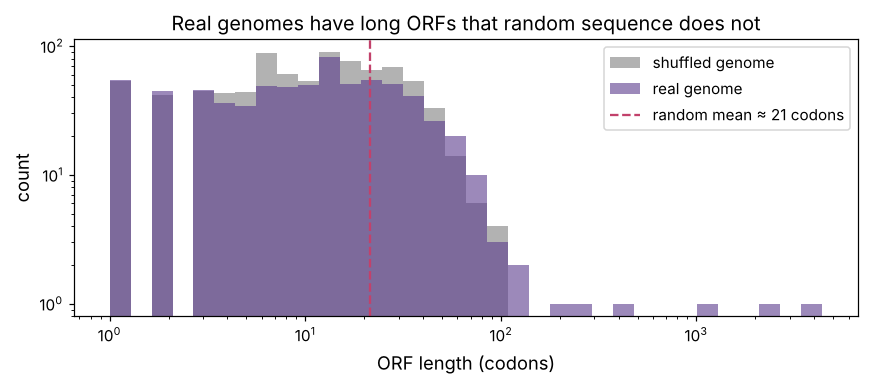

ORFs of 100+ codons: real 9, shuffled 1


In [9]:
rng = np.random.default_rng(1)
real = [o[3] for o in find_orfs(cov.seq, 1)]
shuffled_seq = "".join(rng.permutation(list(str(cov.seq))))
shuf = [o[3] for o in find_orfs(shuffled_seq, 1)]
fig, ax = plt.subplots(figsize=(8, 3.6))
bins = np.logspace(0, np.log10(max(real)), 35)
ax.hist(shuf, bins, alpha=0.6, color="0.5", label="shuffled genome")
ax.hist(real, bins, alpha=0.6, color="#5b3a8c", label="real genome")
p_stop = 3 / 64
ax.axvline(1 / p_stop, color="#c2416b", ls="--", label=f"random mean ≈ {1 / p_stop:.0f} codons")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("ORF length (codons)"); ax.set_ylabel("count"); ax.legend()
ax.set_title("Real genomes have long ORFs that random sequence does not")
save_fig("orf_stats"); plt.show()
threshold = 100
R["real_long"] = sum(l >= threshold for l in real); R["shuf_long"] = sum(l >= threshold for l in shuf)
print(f"ORFs of 100+ codons: real {sum(l >= threshold for l in real)}, shuffled {sum(l >= threshold for l in shuf)}")

![Figure 1-4. ORF-length distributions for the real SARS-CoV-2 genome and a shuffled copy, on log-log axes. Random sequence rarely exceeds the ~21-codon mean; the real genome has a long tail of genuine genes.](images/orf_stats.png)

The real genome has 9 ORFs of 100+ codons; the shuffled copy has 1. That gap is the signal gene finders exploit, and setting the length threshold is a trade-off between sensitivity and false positives, your first taste of a theme running through all of bioinformatics.

## Summary

| Idea | One line |
|---|---|
| NCBI / FASTA / GenBank | where sequences live and the formats they come in |
| Composition and GC | base counts; GC content varies between and within genomes |
| GC skew | cumulative G−C flips sign at the replication origin |
| k-mers | overlapping words of length k; over/under-representation is signal |
| ORF | ATG to stop with no stop between; long ORFs mark genes |
| Six frames | genes can be on either strand, in any of 3 frames |

:::check
1. A 3,000-base genome is 60% GC. Roughly how many `GC` dinucleotides would you expect by chance? *(About 0.3 × 0.3 × 3000 ≈ 270, if bases were independent.)*
2. Why does cumulative GC skew change sign at the replication origin? *(The two strands are copied differently; the leading strand accumulates a G-vs-C bias, which reverses where replication direction reverses.)*
3. In random DNA, about how long is a typical ORF? *(About 21 codons: a stop occurs every 64/3 codons.)*
4. Why does simple ORF finding work for bacteria but not humans? *(Bacterial genes are intron-free and densely packed; human genes are split into short exons across large introns.)*
5. You find a 300-codon ORF. Is it likely a real gene? *(Yes: such lengths essentially never occur by chance.)*
:::

:::exercise
Write a function that, for a given sequence, finds the **best-scoring frame** by codon usage rather than ORF length: score each of the 6 frames by how closely its codon frequencies match known coding frequencies (use the real SARS-CoV-2 genes to learn the frequencies). Does the coding frame stand out? This is the germ of real gene-prediction scoring.
:::

<details><summary>Solution</summary>

In [10]:
# learn codon frequencies from annotated genes (in-frame)
coding = Counter()
for f in genes:
    cds = str(f.extract(cov.seq))
    coding.update(cds[i:i + 3] for i in range(0, len(cds) - 2, 3))
total = sum(coding.values())
logp = {c: np.log((coding[c] + 1) / (total + 64)) for c in CODE}

def frame_score(s):
    s = str(s)
    return np.mean([logp.get(s[i:i + 3], np.log(1 / (total + 64))) for i in range(0, len(s) - 2, 3)])

test = str(cov.seq[265:13468])        # the ORF1a region (CDS starts at base 266), so it is in frame 0 of this slice
for frame in range(3):
    print(f"frame +{frame}: codon-usage score {frame_score(test[frame:]):.3f}")

frame +0: codon-usage score -3.843
frame +1: codon-usage score -4.378
frame +2: codon-usage score -4.653


The true reading frame scores clearly highest, because real coding sequence uses codons very differently from the other two frames (which are full of rare codons and stops). Real gene finders such as GeneMark and Prodigal combine exactly this kind of codon-usage model with ORF length and signals around the start codon, and are far more accurate than length alone.

</details>